# Проверка корректности и производительности библиотеки pytrosna

Ноутбук воспроизводит эксперименты статьи о библиотеке
[pytrosna](https://pypi.org/project/pytrosna/), реализации формата файлов
временных рядов Trosna на языке Python.

1. Проверка корректности: данные, записанные в файл `.trosna` из pandas,
   Polars и PyArrow, читаются обратно без потерь, а правки и чтение прежних
   версий дают ожидаемый результат.
2. Измерение скорости записи и чтения в зависимости от длины ряда.
3. Измерение объёма файла на одну точку в сравнении с CSV, CSV + gzip,
   Apache Parquet и Apache Arrow IPC.

Все рисунки сохраняются в папку `figures/` в формате PNG и TIFF с
разрешением 600 dpi, результаты измерений сохраняются в `results/`.

In [1]:
import os
import platform
import shutil
import sys
import tempfile
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import pyarrow as pa
import pyarrow.feather as feather
import pyarrow.parquet as pq

import pytrosna

WORK = Path(tempfile.mkdtemp(prefix="pytrosna-bench-"))
FIGURES = Path("figures")
RESULTS = Path("results")
FIGURES.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

print("Python  ", sys.version.split()[0], platform.platform())
print("CPU     ", platform.processor() or platform.machine(), os.cpu_count(), "логических ядер")
for module in (pytrosna, np, pd, pl, pa, matplotlib):
    print(f"{module.__name__:<9}", module.__version__)

Python   3.14.4 Linux-7.0.0-38-generic-x86_64-with-glibc2.43
CPU      x86_64 4 логических ядер
pytrosna  0.1.1
numpy     2.5.3
pandas    3.0.6
polars    2.0.0
pyarrow   25.0.1
matplotlib 3.11.2


## 1. Корректность записи и чтения

Создадим устройство со столбцами всех шести типов формата (`bool`, `int32`,
`int64`, `float32`, `float64`, `string`), в том числе с пропущенными
значениями, запишем его в файл и прочитаем обратно тремя способами.

In [2]:
rng = np.random.default_rng(2026)
n = 50_000
times = pd.date_range("2026-10-08 10:00", periods=n, freq="s", tz="Europe/Moscow", unit="s")
frame = pd.DataFrame(
    {
        "time": times,
        "temperature": np.round(21.5 + np.cumsum(rng.normal(0, 0.02, n)), 2),
        "pressure": rng.normal(101.3, 0.1, n).astype(np.float32),
        "counter": np.arange(n, dtype=np.int64) * 3,
        "level": pd.array(np.where(rng.random(n) < 0.05, None, rng.integers(0, 100, n)), dtype="Int32"),
        "door_open": rng.random(n) < 0.02,
        "status": pd.array(rng.choice(["норма", "проверка", "авария"], n, p=[0.9, 0.09, 0.01]), dtype="string"),
    }
)
path = WORK / "sensors.trosna"
commit = pytrosna.write(path, frame, device="room1", message="загрузка показаний", author="benchmark")
print("коммит", commit.number, commit.short_hash, "строк:", commit.changes.rows_written)
print("размер файла:", path.stat().st_size, "байт")

коммит 1 b6e2e08f744a строк: 50000
размер файла: 251294 байт


In [3]:
f = pytrosna.open(path)
schema = f.device("room1")
print("единица времени:", schema.time_unit, "| часовой пояс:", schema.timezone)
print({c.name: c.data_type.label for c in schema.columns})

back = f.read_pandas(dtype_backend="numpy_nullable")
expected = frame.astype({"temperature": "Float64", "pressure": "Float32", "counter": "Int64", "door_open": "boolean"})
pd.testing.assert_frame_equal(back, expected, check_dtype=False)
print("pandas: прочитано без потерь,", len(back), "строк")

from_polars = f.read_polars()
assert from_polars.height == n
assert from_polars["level"].null_count() == int(frame["level"].isna().sum())
assert from_polars["status"].to_list() == frame["status"].tolist()
print("Polars: прочитано без потерь")

table = f.read_arrow()
assert table.column("counter").to_pylist() == frame["counter"].tolist()
assert np.array_equal(table.column("pressure").to_numpy(), frame["pressure"].to_numpy())
print("PyArrow: прочитано без потерь")

единица времени: s | часовой пояс: Europe/Moscow
{'temperature': 'float64', 'pressure': 'float32', 'counter': 'int64', 'level': 'int32', 'door_open': 'bool', 'status': 'string'}


pandas: прочитано без потерь, 50000 строк


Polars: прочитано без потерь
PyArrow: прочитано без потерь


Запись из Polars и PyArrow в новые файлы и обратное чтение также сохраняют
все значения и метки времени.

In [4]:
for name, data in {"polars": pl.from_pandas(frame), "arrow": pa.Table.from_pandas(frame, preserve_index=False)}.items():
    p = WORK / f"from_{name}.trosna"
    pytrosna.write(p, data, device="room1")
    again = pytrosna.read_pandas(p, dtype_backend="numpy_nullable")
    pd.testing.assert_frame_equal(again, expected, check_dtype=False)
    print(f"{name:>7}: запись и чтение совпадают с исходными данными")

 polars: запись и чтение совпадают с исходными данными


  arrow: запись и чтение совпадают с исходными данными


### Правки, аннотации и чтение прежних версий

Изменения вносятся атомарными транзакциями. Каждая прежняя версия файла
остаётся доступной для чтения, а цепочка хешей коммитов проверяется функцией
`verify`.

In [5]:
with f.edit(message="исправление показаний", author="оператор") as tx:
    tx.update("room1", "2026-10-08 10:00:05", temperature=99.9)
    tx.delete_range("room1", "2026-10-08 10:01:00", "2026-10-08 10:01:59")
    tx.insert("room1", "2026-10-09 00:00:00", temperature=20.0, status="норма")
    tx.annotate("room1", "2026-10-08 10:00:00", "2026-10-08 10:00:30", "прогрев")

now = f.read_pandas()
old = f.read_pandas(as_of=1)
assert len(old) == n and len(now) == n - 60 + 1
assert now.loc[now["time"] == pd.Timestamp("2026-10-08 10:00:05", tz="Europe/Moscow"), "temperature"].item() == 99.9
pd.testing.assert_frame_equal(old.reset_index(drop=True), f.read_pandas(as_of=1))
changes = f.diff(1)
print("изменения после коммита 1:", {k: sum(p.kind.value == k for p in changes.points) for k in ("added", "removed", "changed")})
print("аннотации:", [(a.label, a.note) for a in f.annotations()])
report = pytrosna.verify(path)
print("проверка целостности:", "OK" if report.ok else report.problems, "| коммитов:", report.commits, "| блоков:", report.blocks)
for c in f.commits():
    print(f"  коммит {c.number}: {c.hash[:16]}…  предыдущий {c.prev_hash[:16]}…  {c.message}")

изменения после коммита 1: {'added': 1, 'removed': 60, 'changed': 1}
аннотации: [('прогрев', None)]
проверка целостности: OK | коммитов: 2 | блоков: 3
  коммит 1: b6e2e08f744a988e…  предыдущий 0000000000000000…  загрузка показаний
  коммит 2: df7e7e6e592b6652…  предыдущий b6e2e08f744a988e…  исправление показаний


## 2. Методика измерений

Ряд показаний датчика: шаг 1 с, значения температуры получены случайным
блужданием и округлены до 0,01, что соответствует типичному измерительному
каналу. Для каждой длины ряда $n$ измеряется время записи файла из
`pandas.DataFrame` и время чтения обратно в `pandas.DataFrame`; из трёх
повторов берётся наименьшее время. Для сравнения теми же вызовами pandas
и PyArrow записываются и читаются файлы CSV, CSV + gzip, Apache Parquet
и Apache Arrow IPC (Feather v2) со сжатием Zstandard.

Объём на точку вычисляется в битах как $b = 8S / n$, где $S$ обозначает
размер файла в байтах. На рисунке по оси ординат отложен показатель $k$
в записи $b = 2^k$: шкала логарифмическая по основанию 2, рост $k$ на
единицу означает удвоение объёма.

In [6]:
SIZES = [1_000, 3_000, 10_000, 30_000, 100_000, 300_000, 1_000_000]
REPEATS = 3


def sensor_series(n: int, seed: int = 1) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    t = pd.date_range("2026-10-08", periods=n, freq="s", tz="UTC", unit="s")
    v = np.round(20 + np.cumsum(rng.normal(0, 0.02, n)), 2)
    return pd.DataFrame({"time": t, "value": v})


FORMATS = {
    "Trosna, zstd": (
        lambda df, p: pytrosna.write(p, df, device="sensor", sync=False),
        lambda p: pytrosna.read_pandas(p),
        ".trosna",
    ),
    "Trosna, lz4": (
        lambda df, p: pytrosna.write(p, df, device="sensor", sync=False, codec="lz4"),
        lambda p: pytrosna.read_pandas(p),
        ".trosna",
    ),
    "Parquet, zstd": (
        lambda df, p: df.to_parquet(p, compression="zstd", index=False),
        lambda p: pd.read_parquet(p),
        ".parquet",
    ),
    "Arrow IPC, zstd": (
        lambda df, p: feather.write_feather(df, p, compression="zstd"),
        lambda p: feather.read_feather(p),
        ".arrow",
    ),
    "CSV, gzip": (
        lambda df, p: df.to_csv(p, index=False, compression="gzip"),
        lambda p: pd.read_csv(p, parse_dates=["time"]),
        ".csv.gz",
    ),
    "CSV": (
        lambda df, p: df.to_csv(p, index=False),
        lambda p: pd.read_csv(p, parse_dates=["time"]),
        ".csv",
    ),
}


def best_time(fn, repeats=REPEATS):
    best = float("inf")
    for _ in range(repeats):
        start = time.perf_counter()
        fn()
        best = min(best, time.perf_counter() - start)
    return best


rows = []
for n in SIZES:
    df = sensor_series(n)
    for name, (write, read, ext) in FORMATS.items():
        p = WORK / f"series{ext}"
        t_write = best_time(lambda: write(df, p))
        size = p.stat().st_size
        t_read = best_time(lambda: read(p))
        rows.append({"format": name, "n": n, "bytes": size, "write_s": t_write, "read_s": t_read})
        p.unlink()
    print(f"n = {n:>9,}: готово".replace(",", " "))

results = pd.DataFrame(rows)
results["bytes_per_point"] = results["bytes"] / results["n"]
results["bits_per_point"] = 8 * results["bytes_per_point"]
results["write_points_per_s"] = results["n"] / results["write_s"]
results["read_points_per_s"] = results["n"] / results["read_s"]
results.to_csv(RESULTS / "benchmark.csv", index=False)
results.pivot(index="n", columns="format", values="bits_per_point").round(1)

n =     1 000: готово


n =     3 000: готово


n =    10 000: готово


n =    30 000: готово


n =   100 000: готово


n =   300 000: готово


n = 1 000 000: готово


format,"Arrow IPC, zstd",CSV,"CSV, gzip","Parquet, zstd","Trosna, lz4","Trosna, zstd"
n,,,,,,
1000,37.8,255.2,28.0,51.7,33.4,27.3
3000,24.1,255.2,27.7,40.7,26.3,19.7
10000,19.6,255.2,27.4,39.7,22.8,14.4
30000,18.2,255.2,27.2,40.1,21.9,14.1
100000,17.6,254.4,27.2,40.6,21.6,12.6
300000,17.5,252.4,27.1,32.4,21.5,12.4
1000000,17.4,251.1,27.0,27.3,21.9,13.0


Скорость записи и чтения pytrosna, миллионов точек в секунду:

In [7]:
trosna = results[results["format"].str.startswith("Trosna")]
summary = trosna.pivot(index="n", columns="format", values=["write_points_per_s", "read_points_per_s"]) / 1e6
summary.round(3)

write_points_per_s              read_points_per_s             
format         Trosna, lz4 Trosna, zstd       Trosna, lz4 Trosna, zstd
n                                                                     
1000                 0.113        0.111             0.306        0.200
3000                 0.361        0.291             0.526        0.527
10000                0.693        0.549             0.686        0.697
30000                0.914        0.897             0.734        0.714
100000               0.873        0.813             0.663        0.648
300000               0.982        0.955             0.560        0.697
1000000              0.981        0.871             0.619        0.624

## 3. Графики

Рисунки выполнены в цвете шириной 17 см (ширина текстового поля
журнальной страницы) и сохранены с разрешением 600 dpi. Кривые различаются
также маркерами и типом линии, поэтому читаются и при печати в оттенках
серого. Палитра Okabe-Ito различима при нарушениях цветового зрения.

In [8]:
CM = 1 / 2.54
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 13.5,
    "axes.labelsize": 13.5,
    "xtick.labelsize": 13.5,
    "ytick.labelsize": 13.5,
    "legend.fontsize": 13,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
})

# Okabe-Ito palette, markers and line styles keep the curves apart in grey print too
STYLE = {
    "Trosna, zstd": dict(color="#0072B2", marker="o", ls="-", lw=2.2, mfc="#0072B2"),
    "Trosna, lz4": dict(color="#56B4E9", marker="s", ls=(0, (5, 2)), lw=1.8, mfc="white"),
    "Parquet, zstd": dict(color="#D55E00", marker="^", ls=(0, (1, 1.5)), lw=1.6, mfc="white"),
    "Arrow IPC, zstd": dict(color="#009E73", marker="D", ls=(0, (6, 2, 1, 2)), lw=1.4, mfc="white"),
    "CSV, gzip": dict(color="#CC79A7", marker="P", ls=(0, (3, 2)), lw=1.4, mfc="white"),
    "CSV": dict(color="#555555", marker="X", ls="-", lw=1.4, mfc="white"),
}


def save(fig, stem):
    from PIL import Image

    png = FIGURES / f"{stem}.png"
    fig.savefig(png, dpi=600, facecolor="white", bbox_inches="tight", pad_inches=0.08)
    image = Image.open(png).convert("RGB")
    image.save(png, dpi=(600, 600), optimize=True)
    image.save(FIGURES / f"{stem}.tiff", dpi=(600, 600), compression="tiff_lzw")
    print(stem, image.size, "пикселей при 600 dpi")


from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter, NullLocator


def legend_below(fig, ax):
    # the legend is placed under the axes so that it never covers the curves
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.0),
               handlelength=3.2, columnspacing=1.4)


def panel_letter(ax, letter):
    # panel label: a white bold letter in a filled circle above the upper left corner
    ax.text(0.0, 1.04, letter, transform=ax.transAxes, ha="center", va="bottom", fontsize=14,
            fontweight="bold", color="white",
            bbox=dict(boxstyle="circle,pad=0.25", fc="#0072B2", ec="none"))


def decimal_comma(value, _pos=None):
    text = f"{value:g}"
    return text.replace(".", ",")


def log_ticks(ax, ticks):
    # readable log-scale ticks: plain numbers with a decimal comma
    ax.yaxis.set_major_locator(FixedLocator(ticks))
    ax.yaxis.set_major_formatter(FuncFormatter(decimal_comma))
    ax.yaxis.set_minor_locator(NullLocator())


def panel(ax, column, ylabel, scale=1.0, formats=FORMATS, log2=False):
    for name in formats:
        part = results[results["format"] == name]
        y = part[column] * scale
        ax.plot(part["n"], np.log2(y) if log2 else y, label=name, ms=5, **STYLE[name])
    ax.set_xscale("log")
    ax.set_xlabel("Длина ряда $n$, точек")
    ax.set_ylabel(ylabel)
    ax.grid(True, which="major", color="#d0d0d0", lw=0.5)

fig_speed (3856, 1869) пикселей при 600 dpi


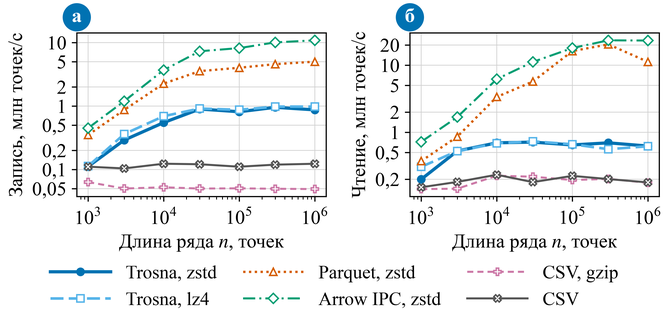

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(17 * CM, 9.0 * CM))
panel(axes[0], "write_points_per_s", "Запись, млн точек/с", 1e-6)
panel(axes[1], "read_points_per_s", "Чтение, млн точек/с", 1e-6)
for ax, letter in zip(axes, "аб"):
    ax.set_yscale("log")
    log_ticks(ax, [0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20])
    panel_letter(ax, letter)
legend_below(fig, axes[0])
fig.tight_layout(rect=(0, 0.14, 1, 0.93))
save(fig, "fig_speed")
plt.show()

fig_size (3864, 2032) пикселей при 600 dpi


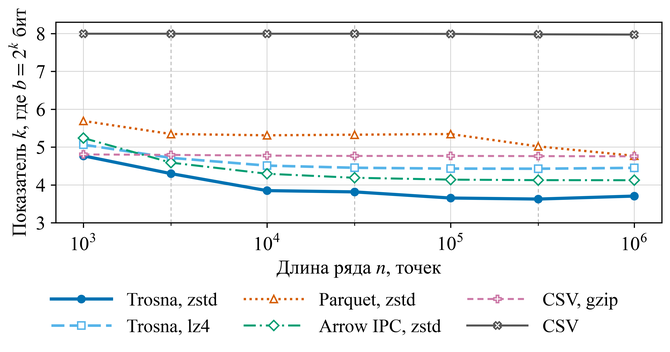

In [10]:
from matplotlib.ticker import MultipleLocator

fig, ax = plt.subplots(figsize=(17 * CM, 8.6 * CM))
# the axis shows the exponent k of b = 2^k bits: a unit step of k doubles the volume
panel(ax, "bits_per_point", "Показатель $k$, где $b = 2^{k}$ бит", log2=True)
ax.yaxis.set_major_locator(MultipleLocator(1))
ax.set_ylim(3, 8.3)
# twice as many vertical grid lines: solid at 10^m, dashed at 3·10^m (the measured lengths)
ax.xaxis.set_minor_locator(FixedLocator([3e3, 3e4, 3e5]))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.grid(True, which="minor", axis="x", color="#b0b0b0", lw=0.6, ls=(0, (4, 3)))
legend_below(fig, ax)
fig.tight_layout(rect=(0, 0.15, 1, 1))
save(fig, "fig_size")
plt.show()

## 4. Выбор кодирований

Библиотека кодирует каждый сегмент столбца всеми допустимыми способами и
сохраняет самый короткий результат. Распределение выбранных кодирований и
объём каждого столбца для файла из раздела 1:

In [11]:
blocks = pytrosna.open(path).blocks()
stats = {}
for block in blocks:
    for s in block.segments:
        entry = stats.setdefault(s.column, {"кодирования": {}, "байт": 0, "точек": 0})
        key = f"{s.encoding.label}+{s.codec.label}"
        entry["кодирования"][key] = entry["кодирования"].get(key, 0) + 1
        entry["байт"] += s.stored_bytes
        entry["точек"] += block.rows
table = pd.DataFrame(
    {
        column: {
            "кодирования (блоков)": ", ".join(f"{k} ×{v}" for k, v in e["кодирования"].items()),
            "бит на точку": round(8 * e["байт"] / e["точек"], 2),
        }
        for column, e in stats.items()
    }
).T
table

,кодирования (блоков),бит на точку
time,"delta-bitpack+zstd ×1, delta-of-delta+none ×2",0.01
temperature,"xor+zstd ×1, xor+none ×2",11.79
pressure,"xor+zstd ×1, xor+none ×1, plain+none ×1",19.46
counter,"delta-bitpack+zstd ×1, delta-bitpack+none ×1, ...",0.0
level,"delta-bitpack+zstd ×1, delta-bitpack+none ×1, ...",7.79
door_open,"rle+zstd ×1, plain+none ×2",0.25
status,"dictionary+zstd ×1, plain+none ×2",0.74


In [12]:
shutil.rmtree(WORK)
print("временные файлы удалены")

временные файлы удалены
